# 04 · Modeling and evaluation

**Purpose.** Train and evaluate next-day AQI forecasters on a chronological split: a persistence
baseline, Linear Regression, XGBoost and an ANN. Report metrics for all cities, excluding
Ahmedabad, per city and per period. Plot XGBoost feature importance and Delhi's actual vs predicted
AQI. Finally, rerun the models on the leaky nowcast variant to show the gap.

**Inputs**
- `../data/processed/features_forecast.csv`, `../data/processed/features_nowcast.csv` (from notebook 03)

**Outputs**
- `../results/forecast_metrics.csv`, `../results/forecast_metrics_excl_ahmedabad.csv`
- `../results/rmse_by_city.csv`, `../results/rmse_by_period.csv`
- `../results/nowcast_with_same_day_pollutants.csv`
- `../results/run_info.json`
- `../results/figures/xgb_feature_importance.png`, `../results/figures/delhi_actual_vs_pred.png`

## Configuration
Same values as the original `src/config.py`.

In [1]:
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")
FIG_DIR = RESULTS_DIR / "figures"

POLLUTANTS = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3"]
TARGET = "AQI"

TRAIN_END = "2018-06-30"
VAL_END = "2018-12-31"

RANDOM_STATE = 42

AQI_BANDS = [(0, 50, "Good"), (51, 100, "Satisfactory"), (101, 200, "Moderate"),
             (201, 300, "Poor"), (301, 400, "Very Poor"), (401, 10_000, "Severe")]

In [2]:
import json
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the forecast features
`float_precision="round_trip"` reads floats back bit for bit.

In [3]:
feats = pd.read_csv(PROCESSED_DIR / "features_forecast.csv", parse_dates=["Date"],
                    float_precision="round_trip")
print(feats.shape)

(14060, 35)


In [4]:
def feature_columns(df: pd.DataFrame) -> list:
    exclude = {"Date", "City", TARGET, "AQI_observed"} | set(POLLUTANTS)
    return [c for c in df.columns if c not in exclude]

cols = feature_columns(feats)
print(len(cols), cols)

24 ['AQI_lag1', 'AQI_lag2', 'AQI_lag3', 'AQI_lag7', 'AQI_rollmean3', 'AQI_rollmean7', 'AQI_rollstd7', 'PM2.5_lag1', 'PM10_lag1', 'NO2_lag1', 'SO2_lag1', 'CO_lag1', 'O3_lag1', 'NH3_lag1', 'month', 'dayofweek', 'dayofyear', 'city_Ahmedabad', 'city_Bengaluru', 'city_Chennai', 'city_Delhi', 'city_Hyderabad', 'city_Lucknow', 'city_Mumbai']


## 2. Chronological split
**Why chronological, no shuffling.** A forecaster is used on days after the ones it was trained on.
A random split would put days from 2019 in training and neighbouring days from 2018 in testing.
Consecutive days are highly correlated, so the model would effectively see the answers and the
test score would be optimistic.

- **Train**: 2015 to 30 Jun 2018
- **Validation**: 1 Jul to 31 Dec 2018, used only for early stopping (XGBoost, ANN)
- **Test**: 1 Jan 2019 to 1 Jul 2020

Two row filters come first:
- **The target is never imputed.** Rows whose AQI was forward-filled (`AQI_observed` is NaN) are
  dropped. Training or scoring on a made-up target would teach and reward the fill rule, not the
  real AQI.
- Rows without the full AQI history (lags and rolling features) are dropped. Gaps in the pollutant
  lag features are kept and handled later: imputation for LR/ANN, natively in XGBoost.

In [5]:
def split(df: pd.DataFrame):
    df = df[df["AQI_observed"].notna()]
    aqi_hist = [c for c in feature_columns(df) if c.startswith("AQI_")]
    df = df.dropna(subset=aqi_hist)
    train = df[df["Date"] <= TRAIN_END]
    val = df[(df["Date"] > TRAIN_END) & (df["Date"] <= VAL_END)]
    test = df[df["Date"] > VAL_END]
    return train, val, test

In [6]:
train, val, test = split(feats)
print(f"Rows  train={len(train)}  val={len(val)}  test={len(test)}  features={len(cols)}")
pd.DataFrame({name: [part["Date"].min().date(), part["Date"].max().date(), len(part)]
              for name, part in [("train", train), ("val", val), ("test", test)]},
             index=["first", "last", "rows"])

Rows  train=6448  val=1261  test=3802  features=24


,train,val,test
first,2015-01-08,2018-07-01,2019-01-01
last,2018-06-30,2018-12-31,2020-07-01
rows,6448,1261,3802


## 3. Metrics
RMSE, MAE and R² on the AQI value, plus **category accuracy**: the share of days where the
predicted AQI falls in the same CPCB category (Good … Severe) as the actual AQI.

In [7]:
def aqi_category(v):
    if pd.isna(v):
        return None
    for lo, hi, name in AQI_BANDS:
        if v <= hi:
            return name
    return "Severe"

def metrics(y_true, y_pred) -> dict:
    cat_true = [aqi_category(v) for v in y_true]
    cat_pred = [aqi_category(v) for v in y_pred]
    return {"RMSE": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
            "MAE": round(float(mean_absolute_error(y_true, y_pred)), 2),
            "R2": round(float(r2_score(y_true, y_pred)), 3),
            "category_accuracy_%": round(100 * np.mean(np.array(cat_true) == np.array(cat_pred)), 1)}

## 4. Models
Each model is wrapped in a small function so the same code can be reused for the nowcast
comparison in section 8.

### 4a. Persistence baseline
Tomorrow's AQI = today's AQI (`AQI_lag1`). Any model worth using has to beat this.

In [8]:
X_tr, X_va, X_te = train[cols].values, val[cols].values, test[cols].values
y_tr, y_va = train[TARGET].values, val[TARGET].values

preds = {"Persistence baseline (AQI_t-1)": test["AQI_lag1"].values}

### 4b. Imputation, fit on the training period only
Linear Regression and the ANN can't take NaNs (gaps in the pollutant lag features), so they get a
median imputer. XGBoost handles missing values natively and uses the raw arrays.

**Why fit on train only.** The imputer's medians (and the ANN's scaler below) are statistics of the
data. Fitting them on validation or test data passes information about the future into training.
They are fit on the training period and only *applied* to validation and test.

In [9]:
def fit_imputer(X_tr, X_va, X_te):
    imp = SimpleImputer(strategy="median").fit(X_tr)
    return imp.transform(X_tr), imp.transform(X_va), imp.transform(X_te)

Xi_tr, Xi_va, Xi_te = fit_imputer(X_tr, X_va, X_te)
print("NaNs before:", np.isnan(X_tr).sum(), " after:", np.isnan(Xi_tr).sum())

NaNs before: 5948  after: 0


### 4c. Linear Regression

In [10]:
def fit_linear(Xi_tr, y_tr, Xi_te):
    lr = LinearRegression().fit(Xi_tr, y_tr)
    return lr.predict(Xi_te)

preds["Linear Regression"] = fit_linear(Xi_tr, y_tr, Xi_te)

### 4d. XGBoost
Gradient-boosted trees on the raw arrays (NaNs handled natively). The validation set is used only
for early stopping: training stops after 100 rounds without improvement in validation error.

In [11]:
def fit_xgb(X_tr, y_tr, X_va, y_va):
    xgb = XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=5,
                       subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                       early_stopping_rounds=100, random_state=RANDOM_STATE)
    xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return xgb

xgb = fit_xgb(X_tr, y_tr, X_va, y_va)
preds["XGBoost"] = xgb.predict(X_te)
print("Best iteration:", xgb.best_iteration)

Best iteration: 417


### 4e. ANN
A feed-forward network: 128-64-32 ReLU layers with dropout 0.2, Adam (lr 1e-3), MSE loss, and early
stopping on validation loss (patience 20, best weights restored). Inputs are imputed and
standardised. The scaler is fit on train only, as above. The target is standardised with the
training mean and std for stable training, then predictions are transformed back to the AQI scale.
The random seed is set right before building the model so results are reproducible on a given
machine.

In [12]:
def build_ann(n_features: int) -> tf.keras.Model:
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model

In [13]:
def fit_ann(Xi_tr, y_tr, Xi_va, y_va, Xi_te):
    scaler = StandardScaler().fit(Xi_tr)
    y_mu, y_sd = y_tr.mean(), y_tr.std()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    ann = build_ann(Xi_tr.shape[1])
    ann.fit(scaler.transform(Xi_tr), (y_tr - y_mu) / y_sd,
            validation_data=(scaler.transform(Xi_va), (y_va - y_mu) / y_sd),
            epochs=300, batch_size=64, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                                        restore_best_weights=True)])
    return ann.predict(scaler.transform(Xi_te), verbose=0).ravel() * y_sd + y_mu

preds["ANN"] = fit_ann(Xi_tr, y_tr, Xi_va, y_va, Xi_te)

## 5. Evaluation on the test set (Jan 2019 to Jul 2020)
### 5a. All 7 cities

In [14]:
y_te = test[TARGET].values
summary = pd.DataFrame([{"model": n, **metrics(y_te, p)} for n, p in preds.items()])
summary.to_csv(RESULTS_DIR / "forecast_metrics.csv", index=False)
summary

,model,RMSE,MAE,R2,category_accuracy_%
0,Persistence baseline (AQI_t-1),41.94,23.81,0.880,75.9
1,Linear Regression,37.86,23.99,0.902,73.8
2,XGBoost,33.48,20.60,0.923,76.9
3,ANN,37.19,26.49,0.905,68.9


### 5b. Excluding Ahmedabad
Ahmedabad's AQI is driven by suspect CO sensor readings (see notebook 01), so metrics are also
reported without it.

In [15]:
no_ahd = (test["City"] != "Ahmedabad").values
summary_ex = pd.DataFrame([{"model": n, **metrics(y_te[no_ahd], p[no_ahd])}
                           for n, p in preds.items()])
summary_ex.to_csv(RESULTS_DIR / "forecast_metrics_excl_ahmedabad.csv", index=False)
summary_ex

,model,RMSE,MAE,R2,category_accuracy_%
0,Persistence baseline (AQI_t-1),31.78,19.53,0.858,77.3
1,Linear Regression,27.95,18.68,0.891,76.1
2,XGBoost,25.54,16.82,0.909,78.0
3,ANN,29.89,22.86,0.875,69.9


### 5c. RMSE by city

In [16]:
per_city = []
for name, p in preds.items():
    for city, idx in test.groupby("City").groups.items():
        mask = test.index.isin(idx)
        per_city.append({"model": name, "city": city,
                         "RMSE": metrics(y_te[mask], p[mask])["RMSE"]})
city_tbl = pd.DataFrame(per_city).pivot(index="city", columns="model", values="RMSE")
city_tbl.to_csv(RESULTS_DIR / "rmse_by_city.csv")
city_tbl

model,ANN,Linear Regression,Persistence baseline (AQI_t-1),XGBoost
city,,,,
Ahmedabad,67.19,74.85,80.93,64.20
Bengaluru,14.52,10.58,12.41,10.97
Chennai,27.70,25.98,30.17,25.40
Delhi,40.13,41.87,47.30,37.95
Hyderabad,24.12,14.13,13.68,12.67
Lucknow,36.73,40.31,46.15,34.24
Mumbai,29.04,17.96,21.04,19.32


### 5d. RMSE by period
The test period includes the 2020 COVID-19 lockdown, a distribution shift, so 2019 and 2020 are
reported separately.

In [17]:
per_period = []
for name, p in preds.items():
    for label, mask in [("2019 (pre-COVID)", test["Date"].dt.year == 2019),
                        ("2020 (incl. lockdown)", test["Date"].dt.year == 2020)]:
        per_period.append({"model": name, "period": label,
                           "RMSE": metrics(y_te[mask.values], p[mask.values])["RMSE"]})
period_tbl = pd.DataFrame(per_period).pivot(index="period", columns="model", values="RMSE")
period_tbl.to_csv(RESULTS_DIR / "rmse_by_period.csv")
period_tbl

model,ANN,Linear Regression,Persistence baseline (AQI_t-1),XGBoost
period,,,,
2019 (pre-COVID),38.59,39.32,44.22,34.85
2020 (incl. lockdown),34.23,34.75,36.97,30.56


## 6. XGBoost feature importance (gain)
Top 12 features by total gain. XGBoost names features `f0, f1, …` when trained on arrays, so these
are mapped back to column names.

In [18]:
imp = (pd.Series(xgb.get_booster().get_score(importance_type="gain"))
         .rename(index=lambda k: cols[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k)
         .sort_values(ascending=False).head(12))
imp

AQI_lag1          796394.250000
AQI_rollmean7     178959.671875
city_Ahmedabad     56963.375000
PM2.5_lag1         55398.007812
AQI_rollmean3      40636.257812
city_Delhi         34404.980469
CO_lag1            29020.451172
city_Bengaluru     18316.128906
NO2_lag1           16165.845703
PM10_lag1          15474.741211
SO2_lag1           13415.531250
city_Hyderabad     13002.006836
dtype: float64

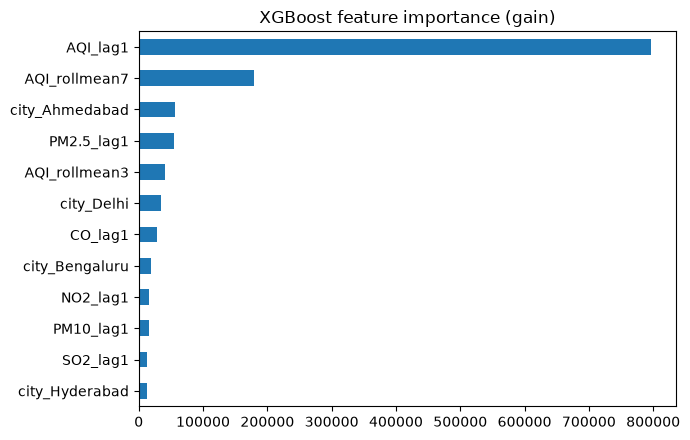

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
imp[::-1].plot.barh(ax=ax)
ax.set_title("XGBoost feature importance (gain)")
fig.tight_layout()
fig.savefig(FIG_DIR / "xgb_feature_importance.png", dpi=150)
plt.show()

## 7. Delhi: actual vs predicted (test period)

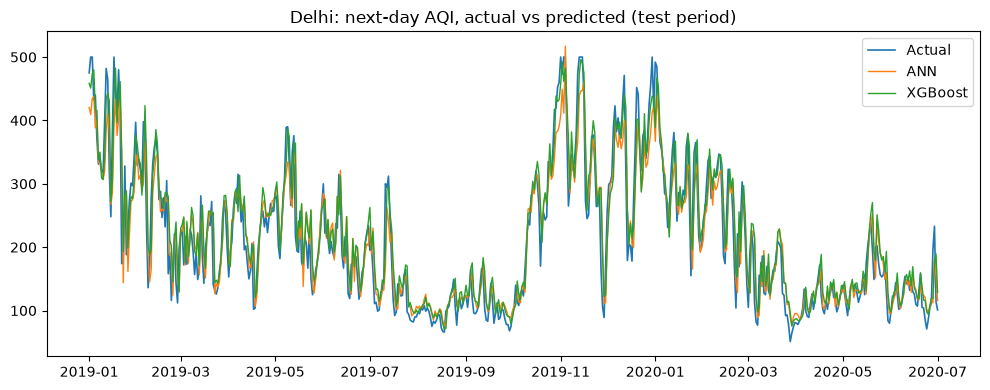

In [20]:
d = test["City"].values == "Delhi"
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(test.loc[d, "Date"], y_te[d], label="Actual", linewidth=1.2)
ax.plot(test.loc[d, "Date"], preds["ANN"][d], label="ANN", linewidth=1)
ax.plot(test.loc[d, "Date"], preds["XGBoost"][d], label="XGBoost", linewidth=1)
ax.set_title("Delhi: next-day AQI, actual vs predicted (test period)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "delhi_actual_vs_pred.png", dpi=150)
plt.show()

## 8. Leakage check: nowcast with same-day pollutants
The same models are retrained on the leaky variant from notebook 03, which adds same-day pollutant
concentrations as inputs. AQI is computed from exactly these values, so the models can
reverse-engineer the AQI formula and the error drops sharply. This is **not a forecast**: those
values are not known in advance. It is shown only to quantify how much leakage inflates the score.
Split, preprocessing and hyperparameters are identical to the forecast setup.

In [21]:
def fit_models(train, val, test, cols) -> dict:
    X_tr, X_va, X_te = train[cols].values, val[cols].values, test[cols].values
    y_tr, y_va = train[TARGET].values, val[TARGET].values
    preds = {"Persistence baseline (AQI_t-1)": test["AQI_lag1"].values}
    Xi_tr, Xi_va, Xi_te = fit_imputer(X_tr, X_va, X_te)
    preds["Linear Regression"] = fit_linear(Xi_tr, y_tr, Xi_te)
    preds["XGBoost"] = fit_xgb(X_tr, y_tr, X_va, y_va).predict(X_te)
    preds["ANN"] = fit_ann(Xi_tr, y_tr, Xi_va, y_va, Xi_te)
    return preds

In [22]:
leaky = pd.read_csv(PROCESSED_DIR / "features_nowcast.csv", parse_dates=["Date"],
                    float_precision="round_trip")
lcols = feature_columns(leaky)
ltr, lva, lte = split(leaky)
print(f"Rows  train={len(ltr)}  val={len(lva)}  test={len(lte)}  features={len(lcols)}")

Rows  train=6448  val=1261  test=3802  features=31


In [23]:
lpreds = fit_models(ltr, lva, lte, lcols)
leak_tbl = pd.DataFrame([{"model": n, "RMSE": metrics(lte[TARGET].values, p)["RMSE"],
                          "R2": metrics(lte[TARGET].values, p)["R2"]}
                         for n, p in lpreds.items() if not n.startswith("Persistence")])
leak_tbl.to_csv(RESULTS_DIR / "nowcast_with_same_day_pollutants.csv", index=False)
leak_tbl

,model,RMSE,R2
0,Linear Regression,31.21,0.933
1,XGBoost,22.13,0.967
2,ANN,28.73,0.944


## 9. Run info
Split sizes and the feature list, for reference.

In [24]:
with open(RESULTS_DIR / "run_info.json", "w") as f:
    json.dump({"train_rows": len(train), "val_rows": len(val), "test_rows": len(test),
               "n_features": len(cols), "features": cols}, f, indent=2)
print(f"train={len(train)}  val={len(val)}  test={len(test)}  features={len(cols)}")

train=6448  val=1261  test=3802  features=24
